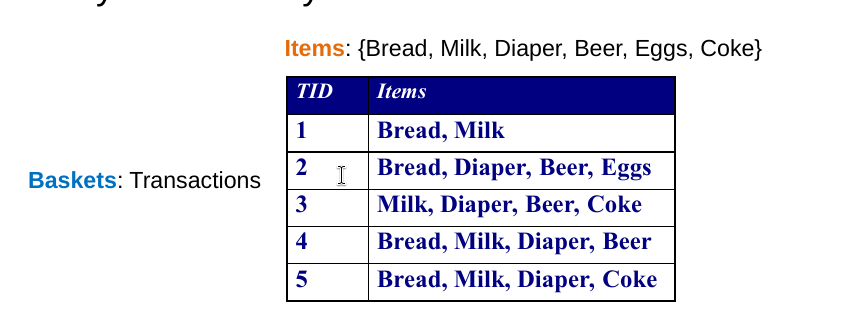

In [1]:
import pandas as pd
import numpy as np

`Support` $s(I)$: number of transactiond that contains Itemset $I$
- `Count`: Frequency of occurence of an itemset
- `Fraction`: percentage
`Frequency Itemset`
- which `itemset` is $s(I) \geq$ minsup

In [2]:
items = set(["Bread", "Milk", "Diaper","Beer", "Eggs", "Coke"])

In [3]:
items

{'Beer', 'Bread', 'Coke', 'Diaper', 'Eggs', 'Milk'}

# The Apriori Pricniple
- if itemset is `frequent` -> all its subsets are `frequent`
- not `frequent` -> all its subsets are not `frequent`
- the support of an itemset never exceeds the support of its subset
$$
\forall X, Y: X \subseteq Y \Rightarrow s(X) \geq s(Y)
$$
- This is knowns as the ***anti-monotone*** property of support

In [4]:
transactions = {
    0: ["Bread", "Milk"],
    1: ["Bread", "Diaper", "Beer", "Eggs"],
    2: ["Milk", "Diaper", "Beer", "Coke"],
    3: ["Bread", "Milk", "Diaper", "Coke"],
    4: ["Bread", "Milk", "Diaper", "Coke"]
}

# Apriori với `mlxtend`

Pipeline gồm 3 bước:
1. `TransactionEncoder` → biến list giao dịch thành ma trận one-hot (mỗi cột = 1 item).
2. `apriori(...)` → sinh các **frequent itemset** thỏa `support >= minsup`.
3. `association_rules(...)` → sinh **luật kết hợp** từ các itemset đó.

In [5]:
import numpy as np
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

## 1. Mã hoá giao dịch (one-hot encoding)

In [6]:
ts = list(transactions.values())
ts

[['Bread', 'Milk'],
 ['Bread', 'Diaper', 'Beer', 'Eggs'],
 ['Milk', 'Diaper', 'Beer', 'Coke'],
 ['Bread', 'Milk', 'Diaper', 'Coke'],
 ['Bread', 'Milk', 'Diaper', 'Coke']]

In [7]:
te = TransactionEncoder()
te_ary = te.fit_transform(ts)

df = pd.DataFrame(te_ary, columns=te.columns_, index=list(transactions.keys()))
df.index.name = "TID"
df

,Beer,Bread,Coke,Diaper,Eggs,Milk
TID,,,,,,
0,False,True,False,False,False,True
1,True,True,False,True,True,False
2,True,False,True,True,False,True
3,False,True,True,True,False,True
4,False,True,True,True,False,True


## 2. Frequent itemsets

$$
s(I) = \frac{\text{số giao dịch chứa } I}{\text{tổng số giao dịch}}
$$

Ở đây chọn `min_support = 0.4` (tức itemset phải xuất hiện ít nhất $0.4 \times 5 = 2$ lần).

In [8]:
MIN_SUPPORT = 0.4

freq_itemsets = apriori(df, min_support=MIN_SUPPORT, use_colnames=True)

# thêm cột phụ cho dễ đọc: k (số item) và count (số giao dịch thực tế)
freq_itemsets["length"] = freq_itemsets["itemsets"].apply(len)
freq_itemsets["count"] = (freq_itemsets["support"] * len(df)).round().astype(int)

freq_itemsets = freq_itemsets.sort_values(["length", "support"], ascending=[True, False]).reset_index(drop=True)
freq_itemsets

,support,itemsets,length,count
0,0.8,frozenset({Bread}),1,4
1,0.8,frozenset({Diaper}),1,4
2,0.8,frozenset({Milk}),1,4
3,0.6,frozenset({Coke}),1,3
4,0.4,frozenset({Beer}),1,2
5,0.6,"frozenset({Bread, Diaper})",2,3
6,0.6,"frozenset({Milk, Bread})",2,3
7,0.6,"frozenset({Coke, Diaper})",2,3
8,0.6,"frozenset({Milk, Coke})",2,3
9,0.6,"frozenset({Milk, Diaper})",2,3


In [9]:
# Xem theo từng mức k giống bảng C_k / F_k trong lý thuyết
for k, group in freq_itemsets.groupby("length"):
    print(f"--- F_{k} ---")
    for _, row in group.iterrows():
        print(f"  {set(row['itemsets'])!s:<45} support = {row['support']:.2f}  (count = {row['count']})")

--- F_1 ---
  {'Bread'}                                     support = 0.80  (count = 4)
  {'Diaper'}                                    support = 0.80  (count = 4)
  {'Milk'}                                      support = 0.80  (count = 4)
  {'Coke'}                                      support = 0.60  (count = 3)
  {'Beer'}                                      support = 0.40  (count = 2)
--- F_2 ---
  {'Bread', 'Diaper'}                           support = 0.60  (count = 3)
  {'Milk', 'Bread'}                             support = 0.60  (count = 3)
  {'Coke', 'Diaper'}                            support = 0.60  (count = 3)
  {'Milk', 'Coke'}                              support = 0.60  (count = 3)
  {'Milk', 'Diaper'}                            support = 0.60  (count = 3)
  {'Beer', 'Diaper'}                            support = 0.40  (count = 2)
  {'Coke', 'Bread'}                             support = 0.40  (count = 2)
--- F_3 ---
  {'Milk', 'Coke', 'Diaper'}                    supp

## 3. Sinh luật kết hợp

Với luật $X \Rightarrow Y$:

$$
\text{confidence}(X \Rightarrow Y) = \frac{s(X \cup Y)}{s(X)}
\qquad
\text{lift}(X \Rightarrow Y) = \frac{\text{confidence}(X \Rightarrow Y)}{s(Y)}
$$

- `lift > 1`: X và Y xuất hiện cùng nhau **nhiều hơn** mức ngẫu nhiên → luật có ý nghĩa.
- `lift = 1`: độc lập. `lift < 1`: loại trừ nhau.

In [10]:
MIN_CONFIDENCE = 0.6

rules = association_rules(freq_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)

cols = ["antecedents", "consequents", "support", "confidence", "lift", "leverage", "conviction"]
rules = rules[cols].sort_values(["confidence", "lift"], ascending=False).reset_index(drop=True)
rules

,antecedents,consequents,support,confidence,lift,leverage,conviction
0,"frozenset({Milk, Diaper})",frozenset({Coke}),0.6,1.000000,1.666667,0.24,inf
1,frozenset({Coke}),"frozenset({Milk, Diaper})",0.6,1.000000,1.666667,0.24,inf
2,"frozenset({Milk, Bread, Diaper})",frozenset({Coke}),0.4,1.000000,1.666667,0.16,inf
3,"frozenset({Coke, Bread})","frozenset({Milk, Diaper})",0.4,1.000000,1.666667,0.16,inf
4,frozenset({Coke}),frozenset({Diaper}),0.6,1.000000,1.250000,0.12,inf
5,frozenset({Coke}),frozenset({Milk}),0.6,1.000000,1.250000,0.12,inf
6,frozenset({Beer}),frozenset({Diaper}),0.4,1.000000,1.250000,0.08,inf
7,"frozenset({Milk, Coke})",frozenset({Diaper}),0.6,1.000000,1.250000,0.12,inf
8,"frozenset({Coke, Diaper})",frozenset({Milk}),0.6,1.000000,1.250000,0.12,inf
9,"frozenset({Coke, Bread})",frozenset({Diaper}),0.4,1.000000,1.250000,0.08,inf


In [11]:
# Chỉ giữ các luật thật sự "mạnh": lift > 1
strong_rules = rules[rules["lift"] > 1].copy()

def fmt(rule):
    return f"{set(rule['antecedents'])} => {set(rule['consequents'])}"

strong_rules["rule"] = strong_rules.apply(fmt, axis=1)
strong_rules[["rule", "support", "confidence", "lift"]]

,rule,support,confidence,lift
0,"{'Milk', 'Diaper'} => {'Coke'}",0.6,1.000000,1.666667
1,"{'Coke'} => {'Milk', 'Diaper'}",0.6,1.000000,1.666667
2,"{'Milk', 'Bread', 'Diaper'} => {'Coke'}",0.4,1.000000,1.666667
3,"{'Coke', 'Bread'} => {'Milk', 'Diaper'}",0.4,1.000000,1.666667
4,{'Coke'} => {'Diaper'},0.6,1.000000,1.250000
5,{'Coke'} => {'Milk'},0.6,1.000000,1.250000
6,{'Beer'} => {'Diaper'},0.4,1.000000,1.250000
7,"{'Milk', 'Coke'} => {'Diaper'}",0.6,1.000000,1.250000
8,"{'Coke', 'Diaper'} => {'Milk'}",0.6,1.000000,1.250000
9,"{'Coke', 'Bread'} => {'Diaper'}",0.4,1.000000,1.250000


## 4. Thử nghiệm với ngưỡng khác

Hạ `min_support` xuống thì số itemset tăng (đúng tính chất anti-monotone), nâng `min_confidence` lên thì số luật giảm.

In [12]:
for minsup in [0.2, 0.4, 0.6, 0.8]:
    f = apriori(df, min_support=minsup, use_colnames=True)
    r = association_rules(f, metric="confidence", min_threshold=0.6) if len(f) else pd.DataFrame()
    print(f"min_support = {minsup:.1f} -> {len(f):>2} frequent itemsets, {len(r):>2} rules")

min_support = 0.2 -> 33 frequent itemsets, 72 rules
min_support = 0.4 -> 17 frequent itemsets, 40 rules
min_support = 0.6 -> 10 frequent itemsets, 16 rules
min_support = 0.8 ->  3 frequent itemsets,  0 rules
